# One-species model

## Model equations

The ODE system is

$$
\begin{aligned}
\dot{F}_f &= -\alpha F_f + \left(1 + b_N\right) \beta C_{2,N} + \left(1 + b_I\right) \beta C_{2,I} - dN F_f \\
\dot{C}_{1,N} &= \alpha \frac{M_N}{M_N+M_I} F_f - \left(\beta + dN + \gamma M_I\right) C_{1,N} \\
\dot{C}_{2,N} &= \beta C_{1,N} - \left(\beta + dN + \gamma M_I\right) C_{2,N} \\
\dot{C}_{1,I} &= \alpha \frac{M_I}{M_N+M_I} F_f + \gamma M_I \left(C_{1,N} + C_{2,N} + C_{2,I}\right) - \left(\beta + dN\right) C_{1,I} \\
\dot{C}_{2,I} &= \beta C_{1,I} - \left(\beta + dN + \gamma M_I\right) C_{2,I} \\
\dot{M}_N &= b_N \beta C_{2,N} - dN M_N \\
\dot{M}_I &= b_I \beta C_{2,I} - dN M_I \\
N &= F_f + C_{1,N} + C_{2,N} + C_{1,I} + C_{2,I} + M_N + M_I
\end{aligned}
$$

The fractional terms above apply when $M_N+M_I>0$. When $M_N+M_I=0$, both care-initiation fluxes are set to zero. In addition,

$$
b_I = \left(1-s\right)b_N
$$

where $s$ represents the proportional reduction in offspring production by infanticidal males.


### Setup

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root, brentq

params = {
    'alpha': 1.0,
    'beta': 1.0,
    'gamma': 0.01,
    'd': 0.001,
    'b_N': 1.0,
    's': 0.6,
}

# Keep the existing figure style shared by both parameter scans.
plot_style = {
    'branch_match_tol': 0.15,
    'branch_lw': 1.8,
    'class_colors': {
        'stable': 'tab:blue',
        'neutral': 'tab:red',
        'unstable': 'tab:red',
    },
    'figure_size': (4, 3),
    'axis_label_fontsize': 14,
    'tick_label_fontsize': 12,
}


def infanticidal_male_frequency(M_N, M_I):
    """Return NaN wherever the total male density is zero."""
    M_N, M_I = np.broadcast_arrays(
        np.asarray(M_N, dtype=float), np.asarray(M_I, dtype=float)
    )
    male_total = M_N + M_I
    return np.divide(
        M_I, male_total, out=np.full_like(male_total, np.nan),
        where=male_total > 0.0,
    )


def male_partner_frequencies(M_N, M_I):
    """Zero weights suppress mating flux when males are absent."""
    male_total = M_N + M_I
    if male_total <= 0.0:
        return 0.0, 0.0
    return M_N / male_total, M_I / male_total


def ecoevo_rhs(time, y, alpha, beta, gamma, d, b_N, s):
    b_I = (1.0 - s) * b_N
    F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I = y
    N = F_f + C1_N + C2_N + C1_I + C2_I + M_N + M_I
    p_N, p_M = male_partner_frequencies(M_N, M_I)

    mating_N = alpha * p_N * F_f
    mating_I = alpha * p_M * F_f

    dF_f = -(mating_N + mating_I) + (1.0 + b_N) * beta * C2_N + (1.0 + b_I) * beta * C2_I - d * N * F_f
    dC1_N = mating_N - (beta + d * N + gamma * M_I) * C1_N
    dC2_N = beta * C1_N - (beta + d * N + gamma * M_I) * C2_N
    dC1_I = mating_I + gamma * M_I * (C1_N + C2_N + C2_I) - (beta + d * N) * C1_I
    dC2_I = beta * C1_I - (beta + d * N + gamma * M_I) * C2_I
    dM_N = b_N * beta * C2_N - d * N * M_N
    dM_I = b_I * beta * C2_I - d * N * M_I

    return np.array([dF_f, dC1_N, dC2_N, dC1_I, dC2_I, dM_N, dM_I], dtype=float)

### Dynamics


{'alpha': 1.0, 'beta': 1.0, 'gamma': 0.01, 'd': 0.001, 'b_N': 1.0, 's': 0.6, 'b_I': 0.4}


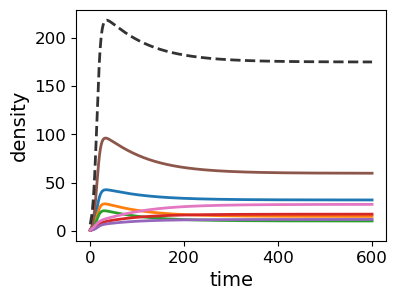

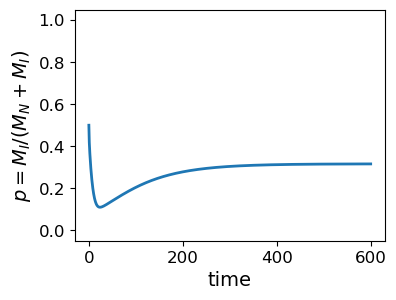

In [19]:
y0 = np.array([
    1.0,  # F_f
    1.0,  # C1_N
    1.0,  # C2_N
    1.0,  # C1_I
    1.0,  # C2_I
    1.0,  # M_N
    1.0,  # M_I
], dtype=float)

t_span = (0.0, 600.0)
t_eval = np.linspace(t_span[0], t_span[1], 2000)

sol = solve_ivp(
    ecoevo_rhs,
    t_span,
    y0,
    args=tuple(params[key] for key in ('alpha', 'beta', 'gamma', 'd', 'b_N', 's')),
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10,
)

if not sol.success:
    raise RuntimeError(sol.message)

F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I = sol.y
N = F_f + C1_N + C2_N + C1_I + C2_I + M_N + M_I
p = infanticidal_male_frequency(M_N, M_I)

print({**params, 'b_I': (1.0 - params['s']) * params['b_N']})

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(sol.t, F_f, lw=2)
ax.plot(sol.t, C1_N, lw=2)
ax.plot(sol.t, C2_N, lw=2)
ax.plot(sol.t, C1_I, lw=2)
ax.plot(sol.t, C2_I, lw=2)
ax.plot(sol.t, M_N, lw=2)
ax.plot(sol.t, M_I, lw=2)
ax.plot(sol.t, N, lw=2, ls='--', color='black', alpha=0.8)
ax.set_xlabel('time', fontsize=14)
ax.set_ylabel('density', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
plt.show()


fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(sol.t, p, linewidth=2)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel('time', fontsize=14)
ax.set_ylabel(r'$p = M_I / (M_N + M_I)$', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
plt.show()

### Setup for bifurcation analysis

The state vector used in the code is

$$
x = \left(F_f,\, C_{1,N},\, C_{2,N},\, C_{1,I},\, C_{2,I},\, M_N,\, M_I\right)^\top
$$

and the ODE system can be written as

$$
\dot{x} = f(x;s)
$$

The parameter $s$ changes only the fecundity of infanticidal males through $b_I=(1-s)b_N$. The care-initiation rate $\alpha$ is constant, shared by both types, and independent of $s$.

For the analytical Jacobian, define the total male density as

$$
M=M_N+M_I
$$

and, for $M>0$, let

$$
p_N=\frac{M_N}{M},\qquad p_M=\frac{M_I}{M}
$$

The derivatives of the frequency terms are

$$
\frac{\partial p_N}{\partial M_N}=\frac{M_I}{M^2},\quad
\frac{\partial p_N}{\partial M_I}=-\frac{M_N}{M^2},\quad
\frac{\partial p_M}{\partial M_N}=-\frac{M_I}{M^2},\quad
\frac{\partial p_M}{\partial M_I}=\frac{M_N}{M^2}
$$

When $M=0$, the care-initiation fluxes and the corresponding derivative terms used by the root solver are set to zero. This convention is not used to determine stability. For $M>0$, using the variable ordering in $x$ above, the rows of the Jacobian are

$$
\begin{aligned}
(J_{1,1},\dots,J_{1,7}) &= \Bigl( -\alpha-d(N+F_f),\, -dF_f,\, (1+b_N)\beta-dF_f,\, -dF_f,\, (1+b_I)\beta-dF_f,\, -dF_f,\, -dF_f \Bigr), \\
(J_{2,1},\dots,J_{2,7}) &= \Bigl( \alpha p_N-dC_{1,N},\, -\beta-\gamma M_I-d(N+C_{1,N}),\, -dC_{1,N},\, -dC_{1,N},\, -dC_{1,N},\, \alpha F_f\frac{M_I}{M^2}-dC_{1,N},\, -\alpha F_f\frac{M_N}{M^2}-(\gamma+d)C_{1,N} \Bigr), \\
(J_{3,1},\dots,J_{3,7}) &= \Bigl( -dC_{2,N},\, \beta-dC_{2,N},\, -\beta-\gamma M_I-d(N+C_{2,N}),\, -dC_{2,N},\, -dC_{2,N},\, -dC_{2,N},\, -(\gamma+d)C_{2,N} \Bigr), \\
(J_{4,1},\dots,J_{4,7}) &= \Bigl( \alpha p_M-dC_{1,I},\, \gamma M_I-dC_{1,I},\, \gamma M_I-dC_{1,I},\, -\beta-d(N+C_{1,I}),\, \gamma M_I-dC_{1,I},\, -\alpha F_f\frac{M_I}{M^2}-dC_{1,I},\, \alpha F_f\frac{M_N}{M^2}+\gamma(C_{1,N}+C_{2,N}+C_{2,I})-dC_{1,I} \Bigr), \\
(J_{5,1},\dots,J_{5,7}) &= \Bigl( -dC_{2,I},\, -dC_{2,I},\, -dC_{2,I},\, \beta-dC_{2,I},\, -\beta-\gamma M_I-d(N+C_{2,I}),\, -dC_{2,I},\, -(\gamma+d)C_{2,I} \Bigr), \\
(J_{6,1},\dots,J_{6,7}) &= \Bigl( -dM_N,\, -dM_N,\, b_N\beta-dM_N,\, -dM_N,\, -dM_N,\, -d(N+M_N),\, -dM_N \Bigr), \\
(J_{7,1},\dots,J_{7,7}) &= \Bigl( -dM_I,\, -dM_I,\, -dM_I,\, -dM_I,\, b_I\beta-dM_I,\, -dM_I,\, -d(N+M_I) \Bigr).
\end{aligned}
$$

For each equilibrium $x^*$, let $\lambda_1,\dots,\lambda_7$ denote the eigenvalues of $J(x^*;s)$, and define the stability margin as

$$
\mu(x^*;s) = \max_i \operatorname{Re}(\lambda_i)
$$

An equilibrium is classified as stable if $\mu< -\varepsilon$, neutral or nonhyperbolic if $|\mu|\le\varepsilon$, and unstable if $\mu>\varepsilon$.

The origin and equilibria without males are classified as unstable based on results obtained separately. At these points, the frequency $p$ is undefined (`NaN`), and stability is not determined from the Jacobian or its eigenvalues.


In [20]:
def male_frequency_derivatives(M_N, M_I, tol=0.0):
    male_total = M_N + M_I
    if male_total <= tol:
        # Solver fallback only; stability at male-free states is supplied externally.
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
    male_total_sq = male_total * male_total
    p_N = M_N / male_total
    p_M = M_I / male_total
    dpN_dMN = M_I / male_total_sq
    dpN_dMI = -M_N / male_total_sq
    dpM_dMN = -M_I / male_total_sq
    dpM_dMI = M_N / male_total_sq
    return p_N, p_M, dpN_dMN, dpN_dMI, dpM_dMN, dpM_dMI


def one_species_equilibrium_residual(y, alpha, beta, gamma, d, b_N, s):
    return ecoevo_rhs(0.0, y, alpha, beta, gamma, d, b_N, s)


def one_species_analytic_jacobian(y, alpha, beta, gamma, d, b_N, s):
    F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I = np.asarray(y, dtype=float)
    b_I = (1.0 - s) * b_N
    N = F_f + C1_N + C2_N + C1_I + C2_I + M_N + M_I
    p_N, p_M, dpN_dMN, dpN_dMI, dpM_dMN, dpM_dMI = male_frequency_derivatives(M_N, M_I)

    return np.array([
        [
            -alpha * (p_N + p_M) - d * (N + F_f),
            -d * F_f,
            (1.0 + b_N) * beta - d * F_f,
            -d * F_f,
            (1.0 + b_I) * beta - d * F_f,
            -d * F_f,
            -d * F_f,
        ],
        [
            alpha * p_N - d * C1_N,
            -beta - gamma * M_I - d * (N + C1_N),
            -d * C1_N,
            -d * C1_N,
            -d * C1_N,
            alpha * F_f * dpN_dMN - d * C1_N,
            alpha * F_f * dpN_dMI - (gamma + d) * C1_N,
        ],
        [
            -d * C2_N,
            beta - d * C2_N,
            -beta - gamma * M_I - d * (N + C2_N),
            -d * C2_N,
            -d * C2_N,
            -d * C2_N,
            -(gamma + d) * C2_N,
        ],
        [
            alpha * p_M - d * C1_I,
            gamma * M_I - d * C1_I,
            gamma * M_I - d * C1_I,
            -beta - d * (N + C1_I),
            gamma * M_I - d * C1_I,
            alpha * F_f * dpM_dMN - d * C1_I,
            alpha * F_f * dpM_dMI + gamma * (C1_N + C2_N + C2_I) - d * C1_I,
        ],
        [
            -d * C2_I,
            -d * C2_I,
            -d * C2_I,
            beta - d * C2_I,
            -beta - gamma * M_I - d * (N + C2_I),
            -d * C2_I,
            -(gamma + d) * C2_I,
        ],
        [
            -d * M_N,
            -d * M_N,
            b_N * beta - d * M_N,
            -d * M_N,
            -d * M_N,
            -d * (N + M_N),
            -d * M_N,
        ],
        [
            -d * M_I,
            -d * M_I,
            -d * M_I,
            -d * M_I,
            b_I * beta - d * M_I,
            -d * M_I,
            -d * (N + M_I),
        ],
    ], dtype=float)


def one_species_equilibrium_metrics(y):
    M_N, M_I = np.asarray(y, dtype=float)[-2:]
    return {
        'N': float(np.sum(y)),
        'p': float(infanticidal_male_frequency(M_N, M_I)),
    }



def equilibrium_family_1sp(y, tol=1e-8):
    _, _, _, _, _, M_N, M_I = np.asarray(y, dtype=float)
    N = float(np.sum(y))
    if N <= tol:
        return 'origin'
    if M_I <= tol and M_N > tol:
        return 'boundary_p0'
    if M_N <= tol and M_I > tol:
        return 'boundary_p1'
    if M_N + M_I <= tol:
        return 'no_males'
    return 'interior'


def classify_stability_margin(stability_margin, eigen_tol=1e-8):
    if stability_margin < -eigen_tol:
        return 'stable'
    if stability_margin > eigen_tol:
        return 'unstable'
    return 'neutral'


def refine_one_species_equilibrium(seed, alpha, beta, gamma, d, b_N, s,
                                   root_tol=1e-12, residual_tol=1e-8, eigen_tol=1e-8):
    seed = np.maximum(np.asarray(seed, dtype=float), 0.0)
    sol = root(
        lambda y: one_species_equilibrium_residual(y, alpha, beta, gamma, d, b_N, s),
        seed,
        jac=lambda y: one_species_analytic_jacobian(y, alpha, beta, gamma, d, b_N, s),
        method='hybr',
        tol=root_tol,
    )
    y_star = np.asarray(sol.x, dtype=float)
    if np.min(y_star) < -1e-8:
        return None
    y_star = np.maximum(y_star, 0.0)
    # Remove tiny solver noise before residual and stability checks.
    y_star[np.abs(y_star) < 1e-12] = 0.0
    residual = one_species_equilibrium_residual(y_star, alpha, beta, gamma, d, b_N, s)
    residual_norm = float(np.linalg.norm(residual, ord=np.inf))
    if (not np.all(np.isfinite(y_star))) or not np.isfinite(residual_norm) or residual_norm > residual_tol:
        return None
    family = equilibrium_family_1sp(y_star)
    metrics = one_species_equilibrium_metrics(y_star)
    if family in ('origin', 'no_males'):
        # Instability is supplied externally, rather than inferred from a Jacobian.
        stability_class = 'unstable'
        stability_margin = np.nan
        J = None
        eigvals = None
        metrics['p'] = np.nan
    else:
        J = one_species_analytic_jacobian(y_star, alpha, beta, gamma, d, b_N, s)
        if not np.all(np.isfinite(J)):
            return None
        J[np.abs(J) < 1e-12] = 0.0
        eigvals = np.linalg.eigvals(J)
        stability_margin = float(np.max(np.real(eigvals)))
        stability_class = classify_stability_margin(stability_margin, eigen_tol=eigen_tol)
    return {
        'y_star': y_star,
        'residual_norm': residual_norm,
        'jacobian': J,
        'eigvals': eigvals,
        'stability_margin': stability_margin,
        'stability_class': stability_class,
        'family': family,
        'N': metrics['N'],
        'p': metrics['p'],
    }


def equilibrium_distance_1sp(y1, y2):
    y1 = np.asarray(y1, dtype=float)
    y2 = np.asarray(y2, dtype=float)
    scale = max(1.0, np.linalg.norm(y1, ord=np.inf), np.linalg.norm(y2, ord=np.inf))
    return float(np.linalg.norm(y1 - y2, ord=np.inf) / scale)


def one_species_seed_bank(previous_equilibria=None):
    seeds = []
    if previous_equilibria is not None:
        for item in previous_equilibria:
            seeds.append(np.asarray(item['y_star'], dtype=float))
    for density_scale in (0.1, 1.0, 10.0, 40.0):
        for p_guess in (0.0, 0.25, 0.5, 0.75, 1.0):
            n_part = 1.0 - p_guess
            i_part = p_guess
            seeds.append(np.array([
                10.0 * density_scale,
                1.0 * density_scale * n_part,
                1.0 * density_scale * n_part,
                1.0 * density_scale * i_part,
                1.0 * density_scale * i_part,
                5.0 * density_scale * n_part,
                5.0 * density_scale * i_part,
            ], dtype=float))
    seeds.extend([
        np.zeros(7, dtype=float),
        np.array([10.0, 2.0, 2.0, 0.0, 0.0, 8.0, 0.0], dtype=float),
        np.array([10.0, 0.0, 0.0, 2.0, 2.0, 0.0, 8.0], dtype=float),
        np.array([20.0, 2.0, 2.0, 2.0, 2.0, 10.0, 10.0], dtype=float),
    ])
    return seeds


def find_one_species_equilibria(alpha, beta, gamma, d, b_N, s,
                                previous_equilibria=None, dedupe_tol=1e-6):
    equilibria = []
    for seed in one_species_seed_bank(previous_equilibria=previous_equilibria):
        result = refine_one_species_equilibrium(seed, alpha, beta, gamma, d, b_N, s)
        if result is None:
            continue
        duplicate = False
        for existing in equilibria:
            if equilibrium_distance_1sp(result['y_star'], existing['y_star']) < dedupe_tol:
                duplicate = True
                break
        if not duplicate:
            equilibria.append(result)
    equilibria.sort(key=lambda item: (item['family'], item['N'], np.nan_to_num(item['p'], nan=-1.0)))
    return equilibria


def build_one_species_branches(records_by_axis, distance_tol):
    branches = []
    active_by_family = {}

    for current_records in records_by_axis:
        current_by_family = {}
        for rec in current_records:
            current_by_family.setdefault(rec['family'], []).append(rec)

        next_active_by_family = {}
        families = sorted(set(active_by_family) | set(current_by_family))
        for family in families:
            active = active_by_family.get(family, [])
            current = current_by_family.get(family, [])
            current.sort(key=lambda rec: (rec['N'], np.nan_to_num(rec['p'], nan=-1.0)))

            if not active:
                next_active = []
                for rec in current:
                    branch = {'family': family, 'records': [rec]}
                    branches.append(branch)
                    next_active.append(branch)
                if next_active:
                    next_active_by_family[family] = next_active
                continue

            # A unique boundary equilibrium at consecutive grid points belongs
            # to the same branch, including when its density approaches zero.
            if family in ('origin', 'boundary_p0', 'boundary_p1') and len(active) == len(current) == 1:
                active[0]['records'].append(current[0])
                next_active_by_family[family] = active
                continue

            candidates = []
            for branch_idx, branch in enumerate(active):
                last_rec = branch['records'][-1]
                for rec_idx, rec in enumerate(current):
                    dist = equilibrium_distance_1sp(last_rec['y_star'], rec['y_star'])
                    if dist <= distance_tol:
                        candidates.append((dist, branch_idx, rec_idx))

            assigned_branches = set()
            assigned_records = set()
            for dist, branch_idx, rec_idx in sorted(candidates):
                if branch_idx in assigned_branches or rec_idx in assigned_records:
                    continue
                active[branch_idx]['records'].append(current[rec_idx])
                assigned_branches.add(branch_idx)
                assigned_records.add(rec_idx)

            next_active = [active[idx] for idx in range(len(active)) if idx in assigned_branches]
            for rec_idx, rec in enumerate(current):
                if rec_idx in assigned_records:
                    continue
                branch = {'family': family, 'records': [rec]}
                branches.append(branch)
                next_active.append(branch)

            if next_active:
                next_active_by_family[family] = next_active

        active_by_family = next_active_by_family

    return branches


def scan_one_species_equilibria(axis_key, values, base_params):
    records_by_axis = []
    previous_equilibria = None
    for value in values:
        scan_params = {**base_params, axis_key: float(value)}
        equilibria = find_one_species_equilibria(
            **scan_params, previous_equilibria=previous_equilibria,
        )
        records_by_axis.append([
            {
                axis_key: float(value),
                'N': eq['N'],
                'p': eq['p'],
                'stability_class': eq['stability_class'],
                'family': eq['family'],
                'stability_margin': eq['stability_margin'],
                'y_star': eq['y_star'].copy(),
            }
            for eq in equilibria
        ])
        previous_equilibria = equilibria
    return records_by_axis


def interpolate_stability_switch_axis(left, right, value_getter, axis_key):
    margin_left = left['stability_margin']
    margin_right = right['stability_margin']
    left_class = left['stability_class']
    right_class = right['stability_class']
    if left_class != 'neutral' and right_class != 'neutral' and margin_left * margin_right < 0.0:
        denom = margin_left - margin_right
        if abs(denom) < 1e-14:
            weight = 0.5
        else:
            weight = margin_left / denom
    else:
        weight = 0.5
    weight = float(np.clip(weight, 0.0, 1.0))
    axis_switch = left[axis_key] + weight * (right[axis_key] - left[axis_key])
    value_switch = value_getter(left) + weight * (value_getter(right) - value_getter(left))
    return axis_switch, value_switch


def plot_branch_chunks_axis(ax, branch_records, value_getter, cfg, axis_key):
    if len(branch_records) == 0:
        return
    if len(branch_records) == 1:
        rec = branch_records[0]
        value = value_getter(rec)
        if np.isfinite(value):
            ax.plot(
                rec[axis_key], value, marker='.', linestyle='None',
                markersize=cfg['branch_lw'],
                color=cfg['class_colors'][rec['stability_class']], zorder=2,
            )
        return

    for left, right in zip(branch_records[:-1], branch_records[1:]):
        left_val = value_getter(left)
        right_val = value_getter(right)
        if not (np.isfinite(left_val) and np.isfinite(right_val)):
            continue

        left_color = cfg['class_colors'][left['stability_class']]
        right_color = cfg['class_colors'][right['stability_class']]

        if left['stability_class'] == right['stability_class']:
            ax.plot(
                [left[axis_key], right[axis_key]], [left_val, right_val],
                color=left_color, lw=cfg['branch_lw'], zorder=2, solid_capstyle='round'
            )
            continue

        axis_switch, value_switch = interpolate_stability_switch_axis(left, right, value_getter, axis_key)
        ax.plot(
            [left[axis_key], axis_switch], [left_val, value_switch],
            color=left_color, lw=cfg['branch_lw'], zorder=2, solid_capstyle='round'
        )
        ax.plot(
            [axis_switch, right[axis_key]], [value_switch, right_val],
            color=right_color, lw=cfg['branch_lw'], zorder=2, solid_capstyle='round'
        )


def plot_one_species_bifurcation_metric_axis(
    branches, value_getter, ylabel, title,
    cfg, axis_key, axis_label, ylim=None, threshold_lines=None,
):
    fig, ax = plt.subplots(figsize=cfg['figure_size'])
    for branch in branches:
        plot_branch_chunks_axis(ax, branch['records'], value_getter, cfg, axis_key)

    ax.set_xlabel(axis_label, fontsize=cfg['axis_label_fontsize'])
    ax.set_ylabel(ylabel, fontsize=cfg['axis_label_fontsize'])
    ax.tick_params(axis='both', labelsize=cfg['tick_label_fontsize'])
    ax.set_title(title)
    ax.set_xlim(cfg[f'{axis_key}_min'], cfg[f'{axis_key}_max'])
    if ylim is not None:
        ax.set_ylim(*ylim)
    else:
        ax.set_ylim(bottom=0.0)
    for line in threshold_lines or []:
        ax.axvline(line['x'], color=line['color'], ls=':', lw=1.6, alpha=0.9, zorder=1)
    plt.show()

### Invasion thresholds

Let $N_N^*$ and $N_I^*$ denote the total densities at the boundary equilibria containing only non-infanticidal and only infanticidal males, respectively. They are obtained as the positive roots of the following equations:

$$
d^3(N_N^*)^3+d^2(\alpha+2\beta)(N_N^*)^2+d\beta(2\alpha+\beta)N_N^*-\alpha\beta^2b_N=0. \tag{S4}
$$

$$
d^2(d+\gamma/2)(N_I^*)^3+d[d(\alpha+2\beta)+\alpha\gamma/2](N_I^*)^2+d\beta(2\alpha+\beta)N_I^*-\alpha\beta^2b_I=0. \tag{S5}
$$

With $b_I=(1-s)b_N$, infanticidal males can invade the non-infanticidal boundary equilibrium when

$$
s<T_{I\mid N}=\frac{\gamma dN_N^*(2\beta+dN_N^*)}{\gamma dN_N^*(2\beta+dN_N^*)+2d(\beta+dN_N^*)^2},
$$

and non-infanticidal males can invade the infanticidal boundary equilibrium when

$$
s>T_{N\mid I}=\frac{(\gamma N_I^*/2)(2\beta+dN_I^*+\gamma N_I^*/2)}{(\beta+dN_I^*+\gamma N_I^*/2)^2}
$$

In each bifurcation diagram, $s=T_{I\mid N}$ is shown as a black dotted line and $s=T_{N\mid I}$ as a green dotted line. In the $s$ scan, $N_I^*$ also depends on $s$, so the threshold is obtained by solving an implicit equation. In the $\gamma$ scan, the boundary equilibrium densities are also updated at each scan value. When $b_I=0$, no positive infanticidal boundary equilibrium exists, so invasion into that equilibrium is not evaluated. Legends are omitted.


In [21]:
def resident_equilibrium_densities(base_params):
    """Nonnegative roots of S4 and S5 (unique when the birth parameter is positive)."""
    alpha = base_params['alpha']
    beta = base_params['beta']
    gamma = base_params['gamma']
    d = base_params['d']
    b_N = base_params['b_N']
    s = base_params['s']
    if min(alpha, beta, d, b_N) <= 0.0 or gamma < 0.0 or not 0.0 <= s <= 1.0:
        raise ValueError('Thresholds require alpha, beta, d, b_N > 0, gamma >= 0, and 0 <= s <= 1.')

    def positive_density(cubic, quadratic, birth):
        if birth == 0.0:
            return 0.0
        linear = d * beta * (2.0 * alpha + beta)
        constant = alpha * beta**2 * birth
        # All nonconstant coefficients are positive, so this brackets the unique root.
        upper = constant / linear
        return brentq(
            lambda N: ((cubic * N + quadratic) * N + linear) * N - constant,
            0.0, upper, xtol=1e-12, rtol=1e-12,
        )

    N_N = positive_density(d**3, d**2 * (alpha + 2.0 * beta), b_N)
    N_I = positive_density(
        d**2 * (d + gamma / 2.0),
        d * (d * (alpha + 2.0 * beta) + alpha * gamma / 2.0),
        (1.0 - s) * b_N,
    )
    return N_N, N_I


def invasion_cost_thresholds(base_params):
    """I invades N for s < I_given_N; N invades I for s > N_given_I."""
    N_N, N_I = resident_equilibrium_densities(base_params)
    beta, gamma, d = (base_params[key] for key in ('beta', 'gamma', 'd'))
    numerator_N = gamma * d * N_N * (2.0 * beta + d * N_N)
    threshold_I_given_N = numerator_N / (
        numerator_N + 2.0 * d * (beta + d * N_N)**2
    )
    reset_I = gamma * N_I / 2.0
    threshold_N_given_I = (
        reset_I * (2.0 * beta + d * N_I + reset_I)
        / (beta + d * N_I + reset_I)**2
        if N_I > 0.0 else np.nan
    )
    return {'I_given_N': threshold_I_given_N, 'N_given_I': threshold_N_given_I}


def invasion_threshold_lines(axis_key, values, base_params):
    """Locate equalities of the supplied invasion conditions in the plotted range."""
    def residual(value, strategy):
        current = {**base_params, axis_key: float(value)}
        return current['s'] - invasion_cost_thresholds(current)[strategy]

    lines = []
    for strategy, color in [('I_given_N', 'black'), ('N_given_I', 'tab:green')]:
        residuals = np.array([residual(value, strategy) for value in values])
        roots = []
        for value, result in zip(values, residuals):
            if np.isfinite(result) and abs(result) <= 1e-12:
                roots.append(float(value))
        for left, right, f_left, f_right in zip(
            values[:-1], values[1:], residuals[:-1], residuals[1:]
        ):
            if np.isfinite(f_left) and np.isfinite(f_right) and f_left * f_right < 0.0:
                roots.append(brentq(
                    lambda value: residual(value, strategy),
                    left, right, xtol=1e-12, rtol=1e-12,
                ))
        distinct_roots = []
        for value in sorted(roots):
            if not distinct_roots or abs(value - distinct_roots[-1]) > 1e-10:
                distinct_roots.append(value)
        lines.extend({'x': value, 'color': color, 'strategy': strategy} for value in distinct_roots)
    return lines


### Equilibria at the baseline parameter values


In [22]:
baseline_equilibria = find_one_species_equilibria(**params)
print(f'baseline equilibrium points collected: {len(baseline_equilibria)}')

baseline equilibrium points collected: 4


### One-parameter bifurcation diagrams along $s$


total equilibrium points collected along s: 932
invasion thresholds along s: {'I_given_N': [0.6491471051516945], 'N_given_I': [0.5411292830926077]}


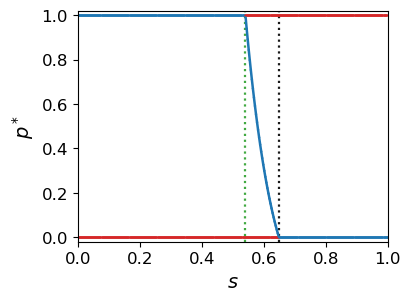

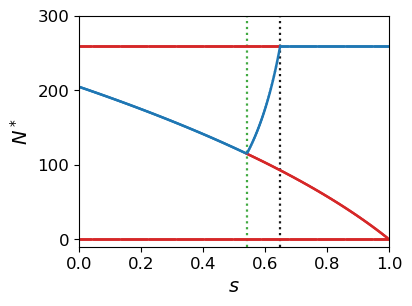

In [23]:
bifurcation_s_base_params = params.copy()
bifurcation_s_config = {
    **plot_style,
    's_min': 0.0,
    's_max': 1.0,
    'n_s': 300,
}

s_values = np.linspace(
    bifurcation_s_config['s_min'],
    bifurcation_s_config['s_max'],
    bifurcation_s_config['n_s'],
)
records_by_s = scan_one_species_equilibria(
    's', s_values, bifurcation_s_base_params,
)
branches_s = build_one_species_branches(
    records_by_s, bifurcation_s_config['branch_match_tol'],
)
print(f'total equilibrium points collected along s: {sum(map(len, records_by_s))}')

threshold_lines_s = invasion_threshold_lines(
    's', s_values, bifurcation_s_base_params,
)
print('invasion thresholds along s:', {
    strategy: [line['x'] for line in threshold_lines_s if line['strategy'] == strategy]
    for strategy in ('I_given_N', 'N_given_I')
})

plot_one_species_bifurcation_metric_axis(
    branches_s,
    value_getter=lambda rec: rec['p'],
    ylabel=r'$p^*$',
    title="",
    cfg=bifurcation_s_config,
    axis_key='s',
    threshold_lines=threshold_lines_s,
    axis_label=r'$s$',
    ylim=(-0.02, 1.02),
)

plot_one_species_bifurcation_metric_axis(
    branches_s,
    value_getter=lambda rec: rec['N'],
    ylabel=r'$N^*$',
    title="",
    cfg=bifurcation_s_config,
    axis_key='s',
    threshold_lines=threshold_lines_s,
    axis_label=r'$s$',
    ylim=(-10, 300),
)

### One-parameter bifurcation diagrams along $\gamma$


total equilibrium points collected along gamma: 990
invasion thresholds along gamma: {'I_given_N': [0.008107243151807721], 'N_given_I': [0.013932074546923773]}


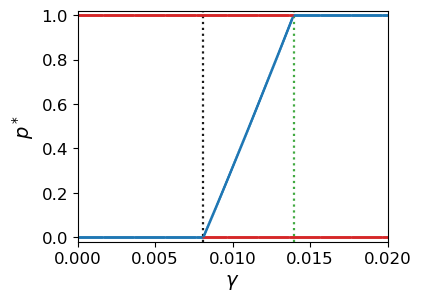

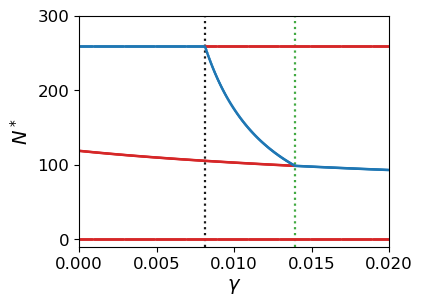

In [24]:
bifurcation_gamma_base_params = params.copy()
bifurcation_gamma_config = {
    **plot_style,
    'gamma_min': 0.0,
    'gamma_max': 0.02,
    'n_gamma': 301,
}

gamma_values = np.linspace(
    bifurcation_gamma_config['gamma_min'],
    bifurcation_gamma_config['gamma_max'],
    bifurcation_gamma_config['n_gamma'],
)
records_by_gamma = scan_one_species_equilibria(
    'gamma', gamma_values, bifurcation_gamma_base_params,
)
branches_gamma = build_one_species_branches(
    records_by_gamma, bifurcation_gamma_config['branch_match_tol'],
)
print(f'total equilibrium points collected along gamma: {sum(map(len, records_by_gamma))}')

threshold_lines_gamma = invasion_threshold_lines(
    'gamma', gamma_values, bifurcation_gamma_base_params,
)
print('invasion thresholds along gamma:', {
    strategy: [line['x'] for line in threshold_lines_gamma if line['strategy'] == strategy]
    for strategy in ('I_given_N', 'N_given_I')
})

plot_one_species_bifurcation_metric_axis(
    branches_gamma,
    value_getter=lambda rec: rec['p'],
    ylabel=r'$p^*$',
    title="",
    cfg=bifurcation_gamma_config,
    axis_key='gamma',
    threshold_lines=threshold_lines_gamma,
    axis_label=r'$\gamma$',
    ylim=(-0.02, 1.02),
)

plot_one_species_bifurcation_metric_axis(
    branches_gamma,
    value_getter=lambda rec: rec['N'],
    ylabel=r'$N^*$',
    title="",
    cfg=bifurcation_gamma_config,
    axis_key='gamma',
    threshold_lines=threshold_lines_gamma,
    axis_label=r'$\gamma$',
    ylim=(-10, 300),
)